# Advanced Data Analysis – VoltVision

## Step 1: Import Required Libraries

In this step, we import the Python libraries required for data analysis and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 2: Load the Cleaned Dataset

In this step, we load the cleaned EV charging dataset using Pandas.

In [2]:
df = pd.read_csv("../data/processed/ev_charging_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (1320, 27)


## Step 3: Dataset Overview

In this step, we inspect the dataset structure, column names, data types, and memory usage.

In [3]:
print("Dataset Information:")
print("-" * 50)

df.info()

Dataset Information:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 27 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   User ID                                   1320 non-null   object 
 1   Vehicle Model                             1320 non-null   object 
 2   Battery Capacity (kWh)                    1320 non-null   float64
 3   Charging Station ID                       1320 non-null   object 
 4   Charging Station Location                 1320 non-null   object 
 5   Charging Start Time                       1320 non-null   object 
 6   Charging End Time                         1320 non-null   object 
 7   Energy Consumed (kWh)                     1320 non-null   float64
 8   Charging Duration (hours)                 1320 non-null   float64
 9   Charging Rate (kW)                 

## Step 4: Statistical Summary

In this step, we calculate descriptive statistics for all numerical columns in the dataset.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Battery Capacity (kWh),1320.0,74.534692,20.626914,1.532807,62.000000,75.000000,85.000000,193.003074
Energy Consumed (kWh),1320.0,42.645320,21.843794,0.045772,24.868084,42.691405,60.545496,152.238758
Charging Duration (hours),1320.0,2.269377,1.061037,0.095314,1.397623,2.258136,3.112806,7.635145
Charging Rate (kW),1320.0,25.945043,13.656504,1.472549,14.431294,25.603799,36.955838,97.342255
Charging Cost (USD),1320.0,22.551352,10.751494,0.234317,13.368141,22.076360,31.646044,69.407743
State of Charge (Start %),1311.0,48.654553,23.431086,2.325959,27.731774,47.992183,68.736181,98.332795
State of Charge (End %),1297.0,74.254404,15.594023,7.604224,61.931297,75.079750,87.470102,99.986604
Distance Driven (since last charge) (km),1320.0,153.529942,83.826126,0.862361,81.931571,152.259867,221.962330,398.364775
Temperature (°C),1320.0,15.263591,14.831216,-10.724770,2.800664,14.630846,27.981810,73.169588
Vehicle Age (years),1320.0,3.612843,2.309824,0.000000,2.000000,4.000000,6.000000,11.688592


## Step 5: Numerical Features Distribution

In this step, we visualize the distribution of numerical features using histograms to understand their spread and frequency.

In [5]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Total Numerical Columns:", len(numerical_columns))
print("\nNumerical Columns:")
print(list(numerical_columns))

Total Numerical Columns: 17

Numerical Columns:
['Battery Capacity (kWh)', 'Energy Consumed (kWh)', 'Charging Duration (hours)', 'Charging Rate (kW)', 'Charging Cost (USD)', 'State of Charge (Start %)', 'State of Charge (End %)', 'Distance Driven (since last charge) (km)', 'Temperature (°C)', 'Vehicle Age (years)', 'Calculated Duration (hours)', 'Duration Difference', 'Expected Energy (kWh)', 'Energy Difference', 'Absolute Energy Difference', 'Cost per kWh', 'Energy to Battery Capacity (%)']


## Step 6: Histogram Analysis of Numerical Features

In this step, we create histograms to visualize the distribution of numerical features and identify their spread, concentration, and skewness.

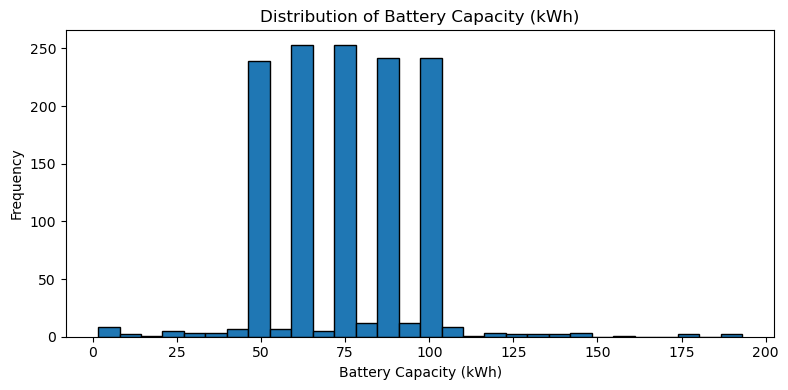

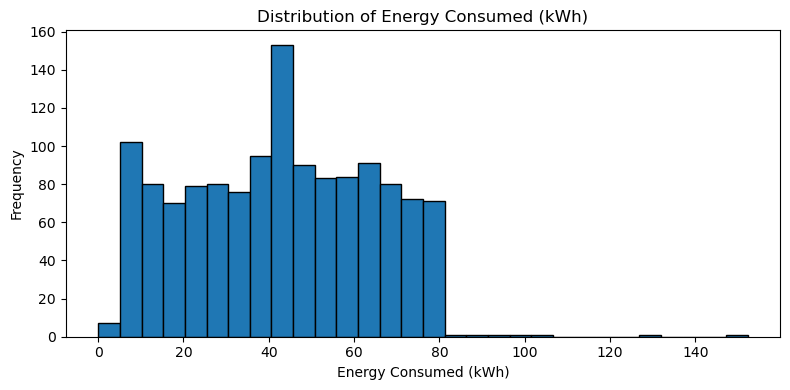

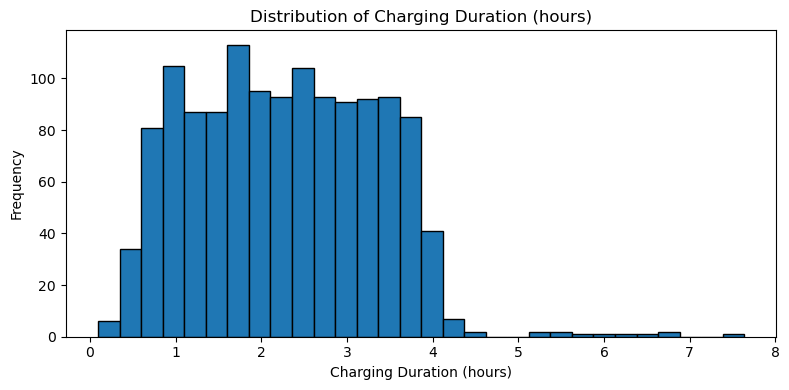

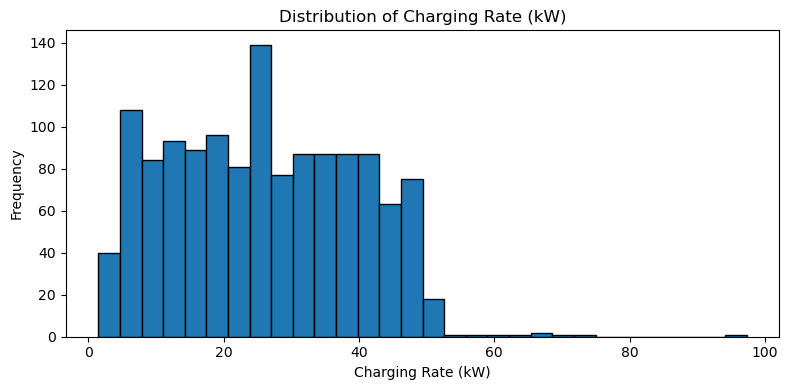

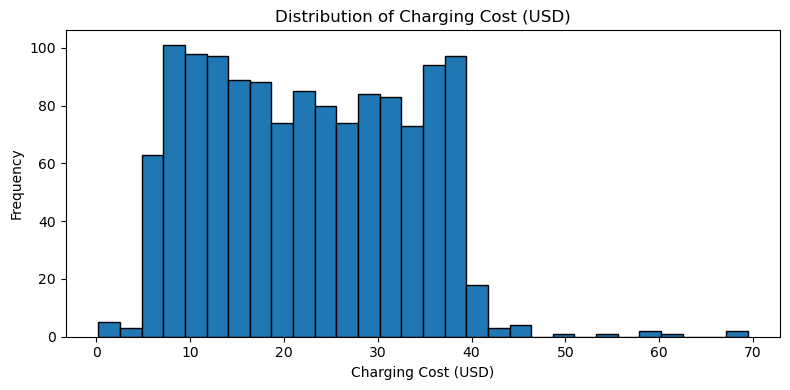

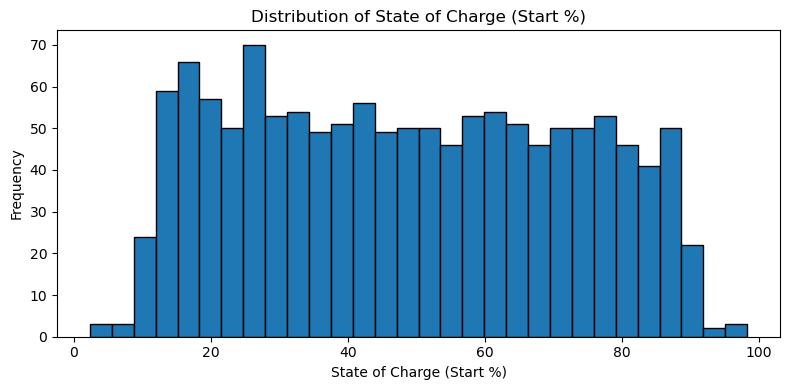

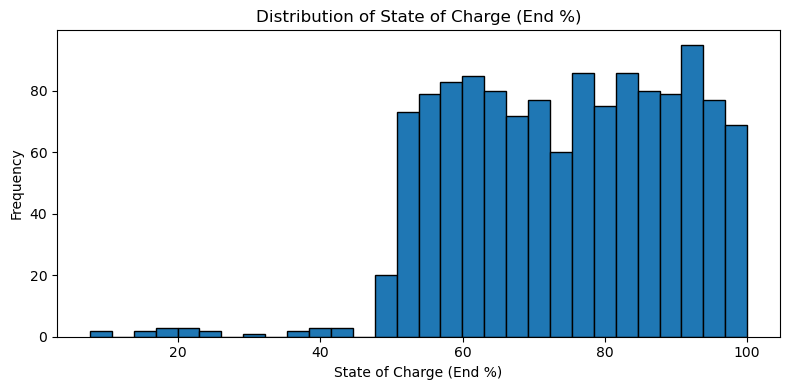

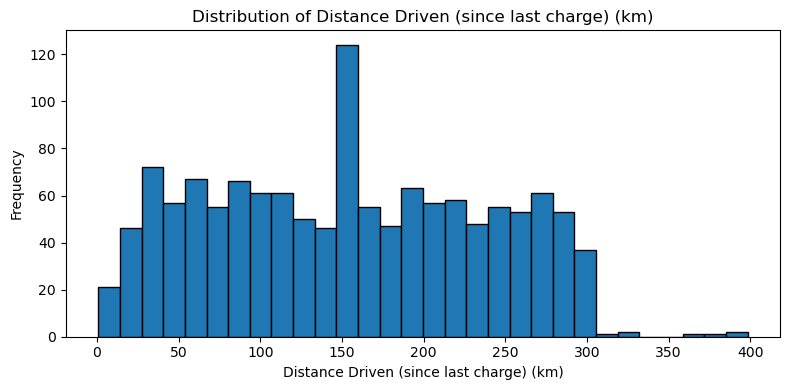

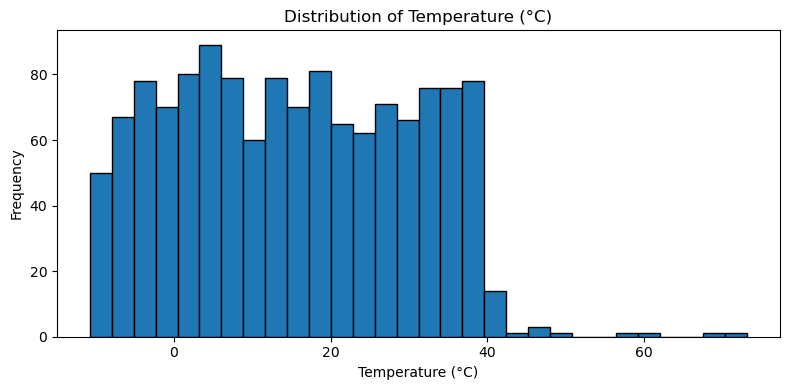

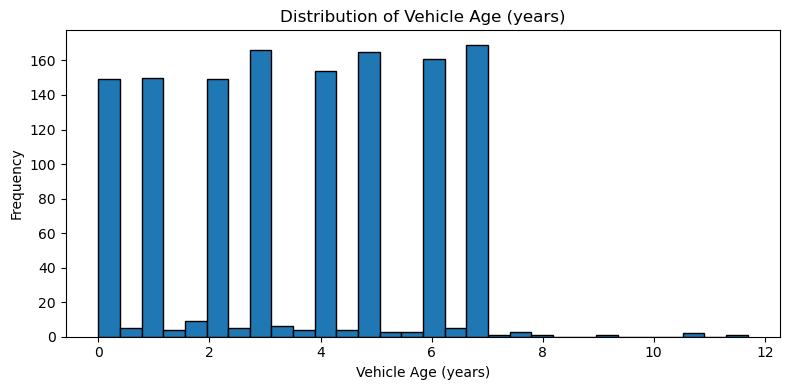

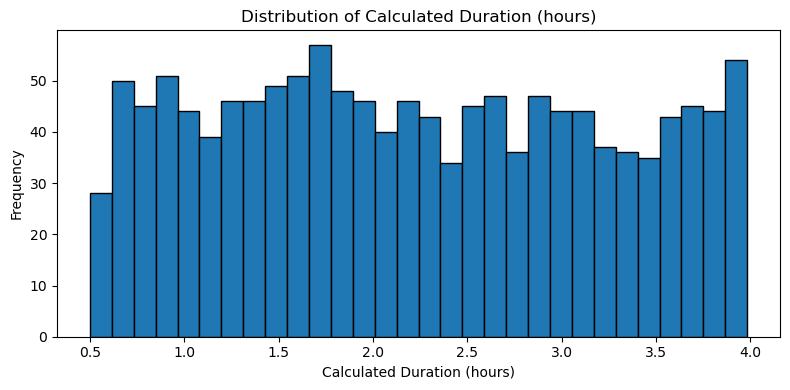

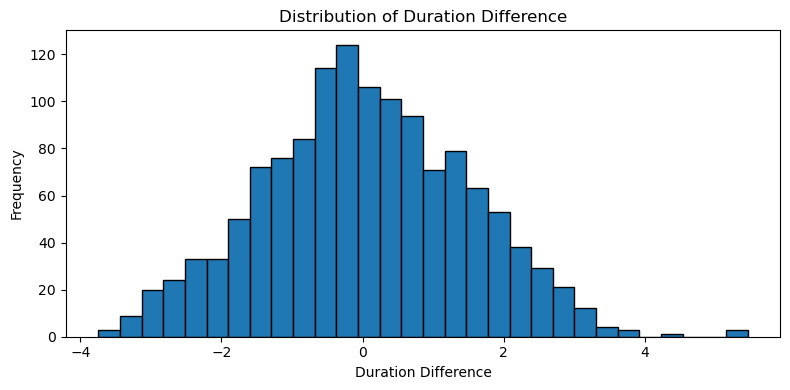

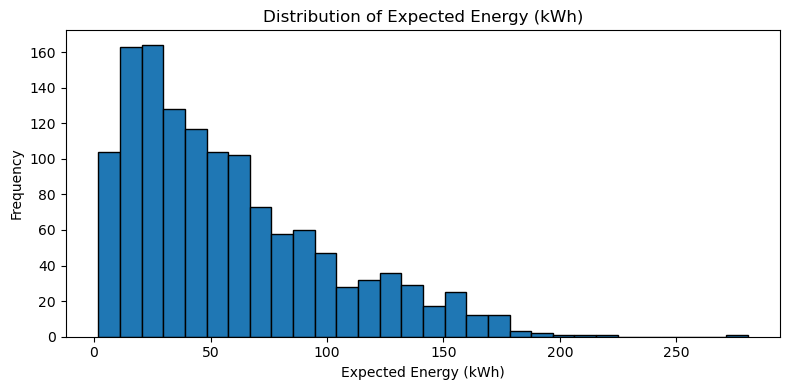

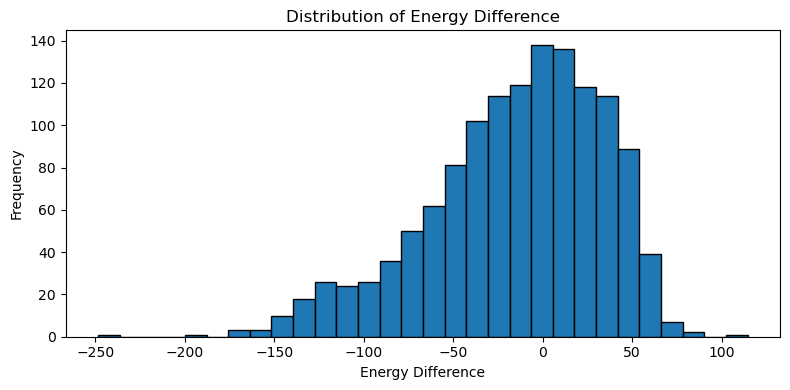

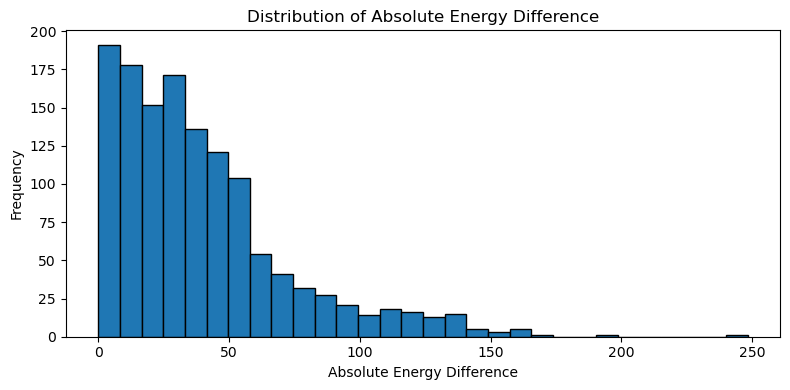

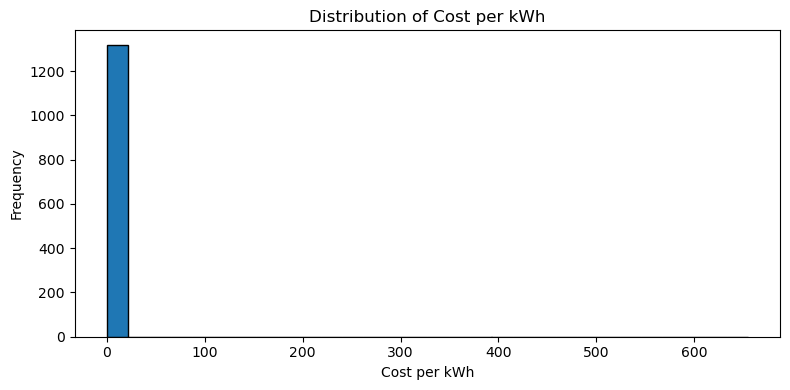

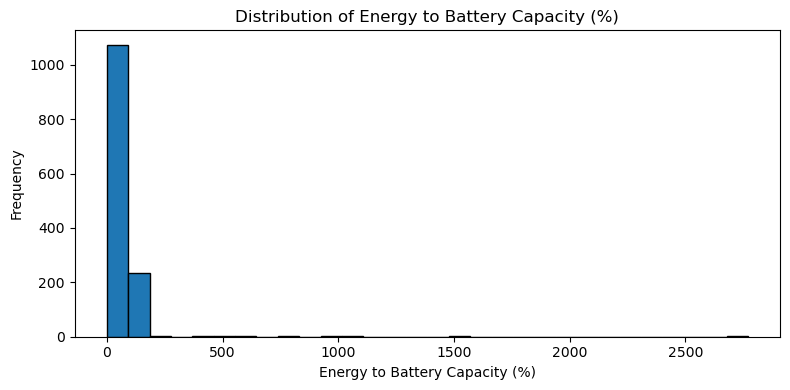

In [6]:
for column in numerical_columns:
    plt.figure(figsize=(8, 4))

    plt.hist(df[column].dropna(), bins=30, edgecolor="black")

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

## Step 7: Correlation Analysis

In this step, we calculate the correlation between numerical features to understand how different variables are related to each other.

In [7]:
correlation_matrix = df[numerical_columns].corr()

correlation_matrix

,Battery Capacity (kWh),Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years),Calculated Duration (hours),Duration Difference,Expected Energy (kWh),Energy Difference,Absolute Energy Difference,Cost per kWh,Energy to Battery Capacity (%)
Battery Capacity (kWh),1.000000,0.000328,-0.024824,0.015691,-0.000492,-0.068342,-0.006239,-0.040130,-0.036411,0.037673,0.038394,-0.044718,0.030219,-0.026217,0.045319,0.023854,-0.372477
Energy Consumed (kWh),0.000328,1.000000,0.027752,-0.040002,-0.007603,-0.018937,0.026215,-0.026378,-0.017993,0.016744,-0.034647,0.044256,-0.053409,0.491022,-0.100287,-0.105352,0.292828
Charging Duration (hours),-0.024824,0.027752,1.000000,-0.012744,0.015902,-0.021251,-0.009901,0.023236,-0.049575,0.001111,0.012288,0.720825,0.006675,0.006510,0.040610,-0.015242,0.000574
Charging Rate (kW),0.015691,-0.040002,-0.012744,1.000000,-0.000924,-0.016195,-0.007881,0.030493,0.012445,-0.049038,0.008314,-0.015057,0.723638,-0.649075,0.449590,-0.020316,-0.012722
Charging Cost (USD),-0.000492,-0.007603,0.015902,-0.000924,1.000000,-0.013805,-0.049496,-0.008318,0.059864,-0.006487,0.004326,0.008599,-0.007848,0.003468,0.007281,0.054177,-0.071032
State of Charge (Start %),-0.068342,-0.018937,-0.021251,-0.016195,-0.013805,1.000000,-0.019885,-0.029327,0.040019,0.032640,-0.016779,-0.003897,-0.020132,0.009130,-0.020034,0.030757,-0.002350
State of Charge (End %),-0.006239,0.026215,-0.009901,-0.007881,-0.049496,-0.019885,1.000000,0.014426,0.007996,0.011034,-0.037612,0.019048,-0.023278,0.031919,0.017203,0.017398,0.037307
Distance Driven (since last charge) (km),-0.040130,-0.026378,0.023236,0.030493,-0.008318,-0.029327,0.014426,1.000000,-0.022961,-0.030835,0.022483,0.001363,0.039545,-0.046222,0.038020,0.022947,-0.009602
Temperature (°C),-0.036411,-0.017993,-0.049575,0.012445,0.059864,0.040019,0.007996,-0.022961,1.000000,0.026410,-0.037830,-0.009935,-0.018263,0.007936,-0.006213,-0.011908,0.000561
Vehicle Age (years),0.037673,0.016744,0.001111,-0.049038,-0.006487,0.032640,0.011034,-0.030835,0.026410,1.000000,0.023689,-0.015610,-0.027039,0.031030,-0.039653,-0.006284,-0.017521


## Step 8: Correlation Heatmap

In this step, we visualize the correlation matrix using a heatmap to identify positive, negative, and weak relationships between numerical features.

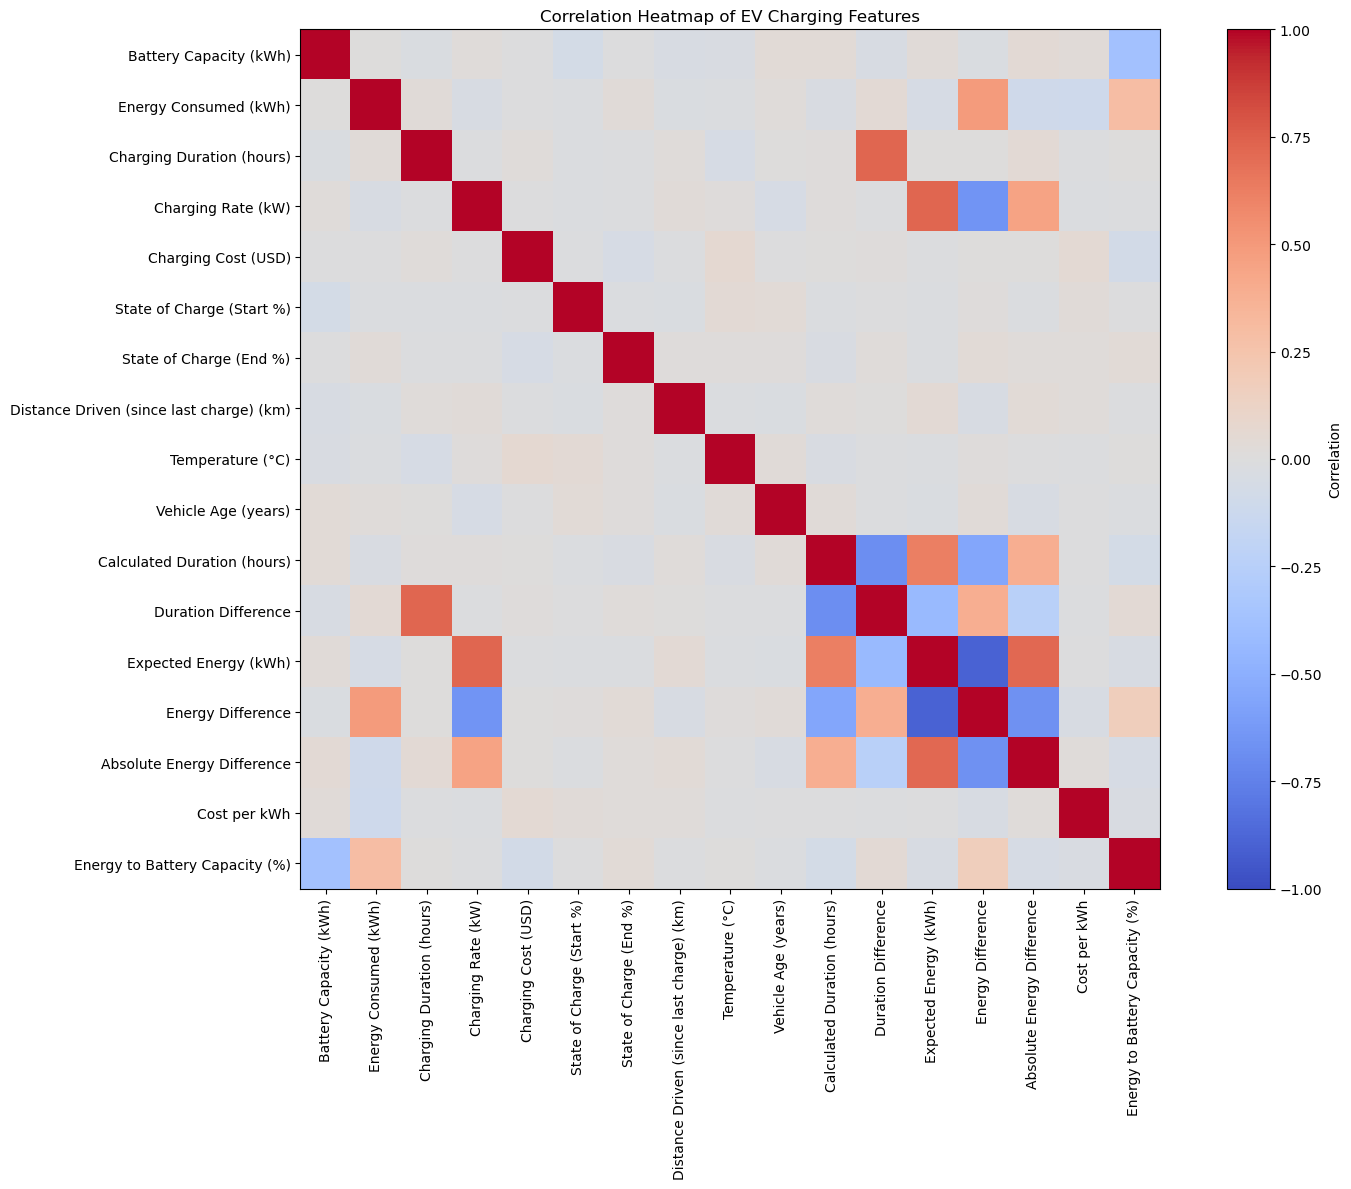

In [8]:
plt.figure(figsize=(16, 12))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap of EV Charging Features")

plt.tight_layout()
plt.show()

## Step 9: Identify Strong Correlations

In this step, we identify the top 10 numerical feature pairs based on the absolute value of their correlation.

This helps us understand which features have relatively stronger linear relationships.

In [9]:
correlation_pairs = (
    correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
)

correlation_pairs.head(10)

,Feature 1,Feature 2,Correlation,Absolute Correlation
126,Expected Energy (kWh),Energy Difference,-0.896129,0.896129
53,Charging Rate (kW),Expected Energy (kWh),0.723638,0.723638
39,Charging Duration (hours),Duration Difference,0.720825,0.720825
127,Expected Energy (kWh),Absolute Energy Difference,0.718631,0.718631
115,Calculated Duration (hours),Duration Difference,-0.684208,0.684208
130,Energy Difference,Absolute Energy Difference,-0.671498,0.671498
54,Charging Rate (kW),Energy Difference,-0.649075,0.649075
116,Calculated Duration (hours),Expected Energy (kWh),0.617213,0.617213
117,Calculated Duration (hours),Energy Difference,-0.553850,0.553850
27,Energy Consumed (kWh),Energy Difference,0.491022,0.491022


## Step 10: Correlation Analysis Interpretation

In this step, we interpret the strongest correlations between numerical features.

Correlation values help us understand the direction and strength of linear relationships between variables.

A correlation does not necessarily indicate causation.

In [10]:
top_correlations = correlation_pairs.head(10).copy()

top_correlations["Relationship"] = np.where(
    top_correlations["Correlation"] > 0,
    "Positive",
    np.where(
        top_correlations["Correlation"] < 0,
        "Negative",
        "No Linear Relationship"
    )
)

top_correlations

,Feature 1,Feature 2,Correlation,Absolute Correlation,Relationship
126,Expected Energy (kWh),Energy Difference,-0.896129,0.896129,Negative
53,Charging Rate (kW),Expected Energy (kWh),0.723638,0.723638,Positive
39,Charging Duration (hours),Duration Difference,0.720825,0.720825,Positive
127,Expected Energy (kWh),Absolute Energy Difference,0.718631,0.718631,Positive
115,Calculated Duration (hours),Duration Difference,-0.684208,0.684208,Negative
130,Energy Difference,Absolute Energy Difference,-0.671498,0.671498,Negative
54,Charging Rate (kW),Energy Difference,-0.649075,0.649075,Negative
116,Calculated Duration (hours),Expected Energy (kWh),0.617213,0.617213,Positive
117,Calculated Duration (hours),Energy Difference,-0.553850,0.553850,Negative
27,Energy Consumed (kWh),Energy Difference,0.491022,0.491022,Positive


## Step 11: Top 10 Correlations Visualization

In this step, we visualize the top 10 feature pairs based on their absolute correlation values.

This chart helps compare the relative strength and direction of relationships between numerical features.

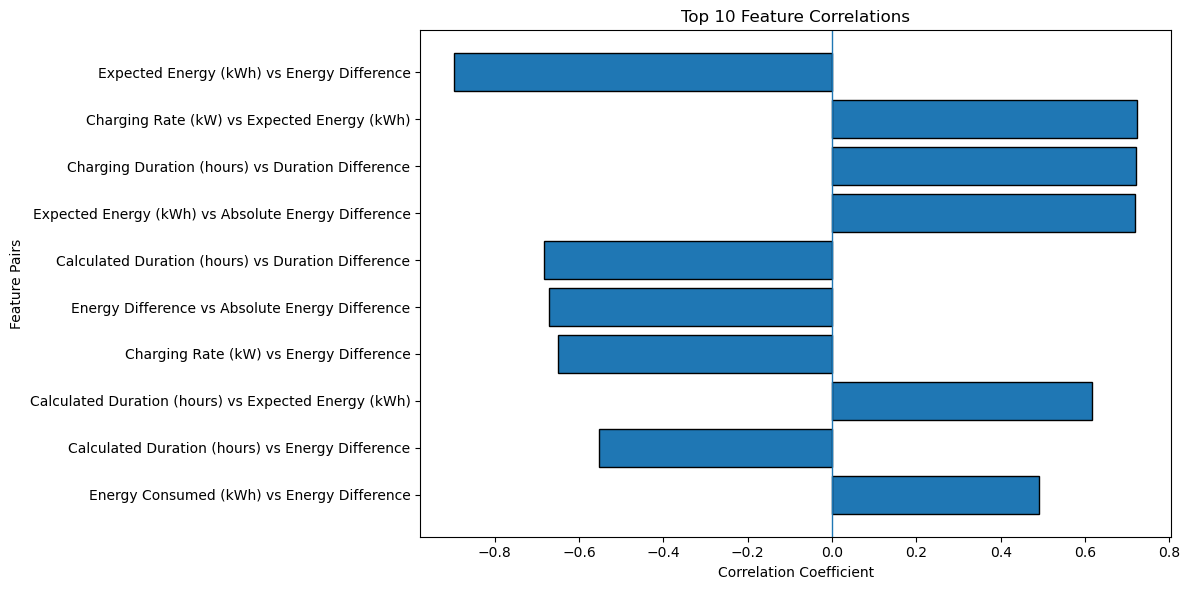

In [11]:
plt.figure(figsize=(12, 6))

labels = (
    top_correlations["Feature 1"]
    + " vs "
    + top_correlations["Feature 2"]
)

plt.barh(
    labels,
    top_correlations["Correlation"],
    edgecolor="black"
)

plt.axvline(0, linewidth=1)
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature Pairs")
plt.title("Top 10 Feature Correlations")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [15]:
# Column names check :
print(df.columns.tolist())

['User ID', 'Vehicle Model', 'Battery Capacity (kWh)', 'Charging Station ID', 'Charging Station Location', 'Charging Start Time', 'Charging End Time', 'Energy Consumed (kWh)', 'Charging Duration (hours)', 'Charging Rate (kW)', 'Charging Cost (USD)', 'Time of Day', 'Day of Week', 'State of Charge (Start %)', 'State of Charge (End %)', 'Distance Driven (since last charge) (km)', 'Temperature (°C)', 'Vehicle Age (years)', 'Charger Type', 'User Type', 'Calculated Duration (hours)', 'Duration Difference', 'Expected Energy (kWh)', 'Energy Difference', 'Absolute Energy Difference', 'Cost per kWh', 'Energy to Battery Capacity (%)']


## Step 12: Numerical Feature Boxplots

In this step, we create boxplots for selected numerical features to examine their spread, median, and potential outliers.

Outliers will be identified for further investigation, not automatically removed.

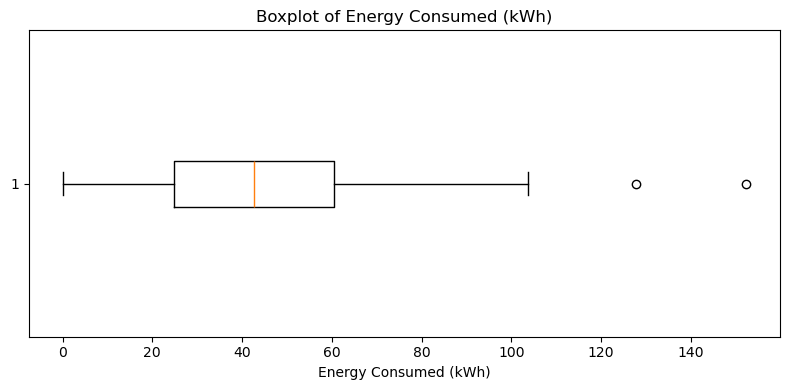

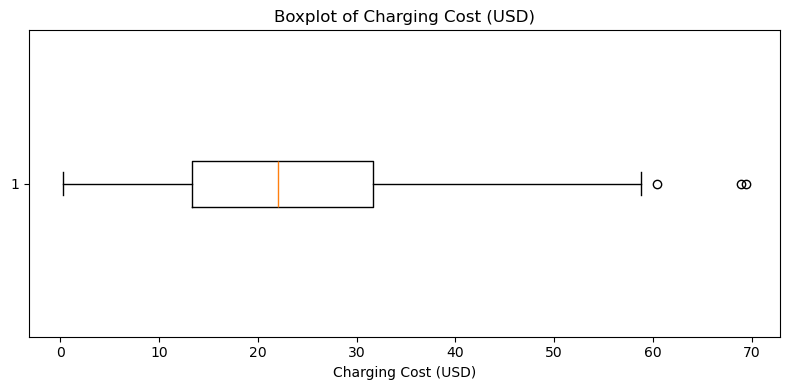

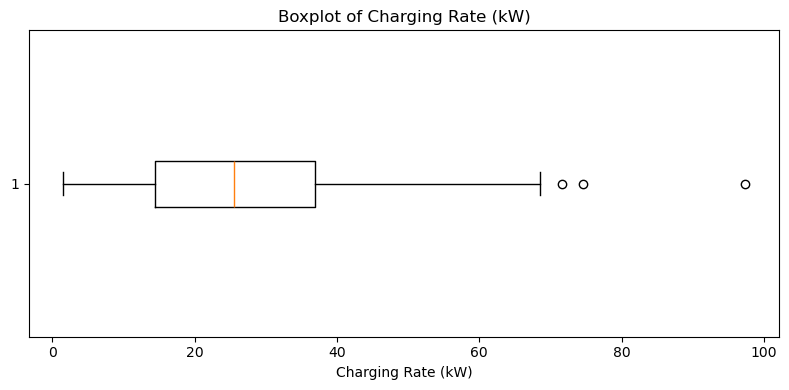

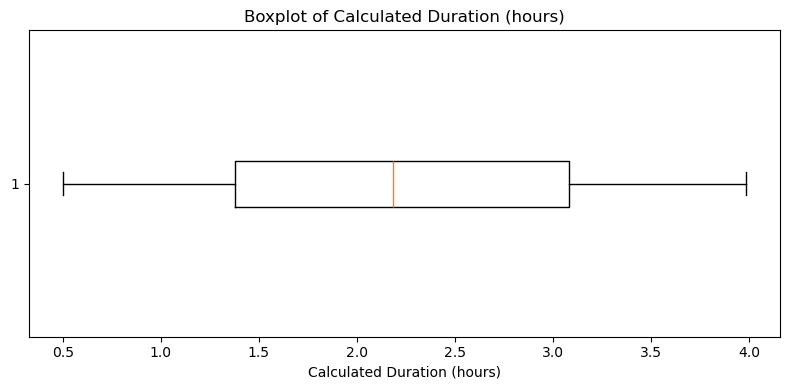

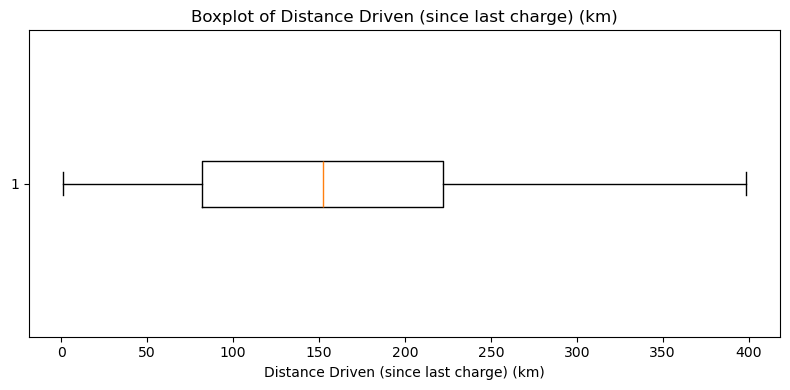

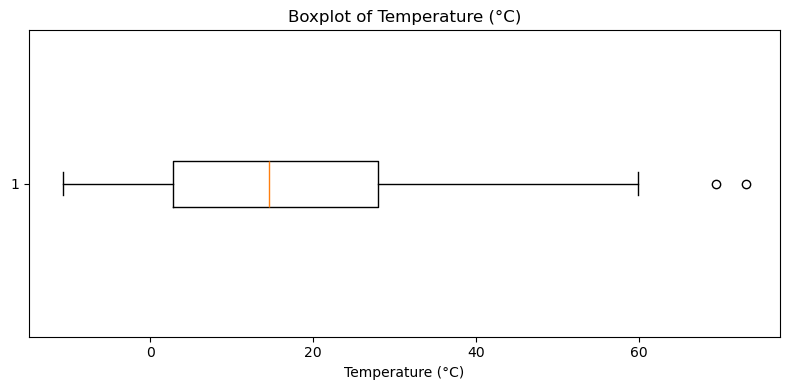

In [16]:
selected_features = [
    "Energy Consumed (kWh)",
    "Charging Cost (USD)",
    "Charging Rate (kW)",
    "Calculated Duration (hours)",
    "Distance Driven (since last charge) (km)",
    "Temperature (°C)"
]

for column in selected_features:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[column].dropna(), vert=False)
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

## Step 13: Outlier Detection Using IQR

In this step, we calculate potential outliers in selected numerical features using the Interquartile Range (IQR) method.

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values outside these bounds are flagged as potential outliers. They will not be removed automatically.

In [17]:
outlier_results = []

for column in selected_features:
    data = df[column].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) | (data > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            (len(outliers) / len(data)) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Energy Consumed (kWh),-28.65,114.06,2,0.15
1,Charging Cost (USD),-14.05,59.06,3,0.23
2,Charging Rate (kW),-19.36,70.74,3,0.23
3,Calculated Duration (hours),-1.18,5.64,0,0.00
4,Distance Driven (since last charge) (km),-128.11,432.01,0,0.00
5,Temperature (°C),-34.97,65.75,2,0.15


## Step 14: Outlier Count Visualization

In this step, we visualize the number of potential outliers detected in each selected numerical feature using the IQR method.

This comparison helps identify which features contain relatively more extreme values.

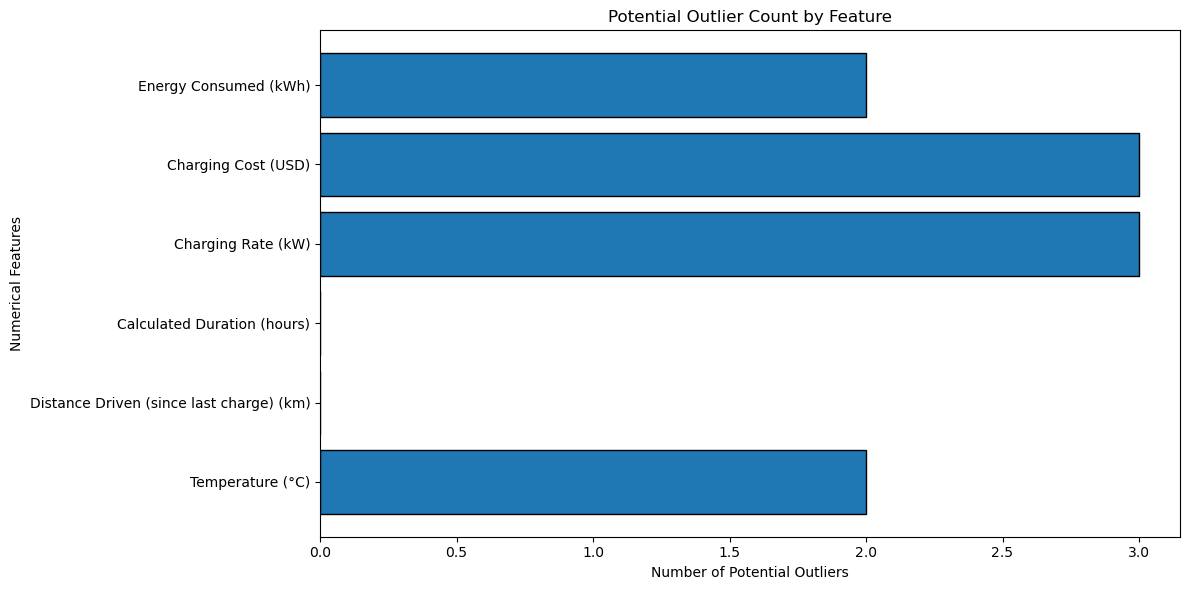

In [18]:
plt.figure(figsize=(12, 6))

plt.barh(
    outlier_summary["Feature"],
    outlier_summary["Outlier Count"],
    edgecolor="black"
)

plt.xlabel("Number of Potential Outliers")
plt.ylabel("Numerical Features")
plt.title("Potential Outlier Count by Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Step 15: Vehicle-wise Performance Analysis

In this step, we compare different vehicle models based on their average energy consumption, average charging cost, and average calculated charging duration.

This analysis helps us understand differences in charging patterns across vehicle models.

In [19]:
vehicle_performance = df.groupby("Vehicle Model").agg(
    Total_Sessions=("User ID", "count"),
    Average_Energy=("Energy Consumed (kWh)", "mean"),
    Average_Cost=("Charging Cost (USD)", "mean"),
    Average_Duration=("Calculated Duration (hours)", "mean")
).round(2)

vehicle_performance

,Total_Sessions,Average_Energy,Average_Cost,Average_Duration
Vehicle Model,,,,
BMW i3,258,42.46,20.78,2.26
Chevy Bolt,256,40.84,22.26,2.26
Hyundai Kona,266,42.83,23.44,2.24
Nissan Leaf,260,42.51,23.65,2.16
Tesla Model 3,280,44.42,22.58,2.20


## Step 16: Vehicle-wise Average Energy Consumption

In this step, we visualize the average energy consumed by each vehicle model.

This comparison helps identify differences in average charging energy across vehicle models.

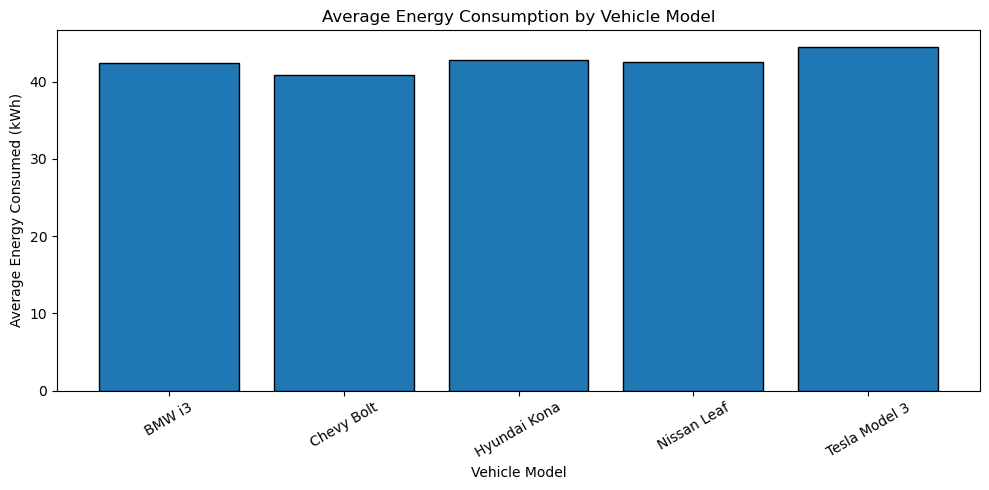

In [20]:
plt.figure(figsize=(10, 5))

plt.bar(
    vehicle_performance.index,
    vehicle_performance["Average_Energy"],
    edgecolor="black"
)

plt.xlabel("Vehicle Model")
plt.ylabel("Average Energy Consumed (kWh)")
plt.title("Average Energy Consumption by Vehicle Model")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 17: Vehicle-wise Average Charging Cost

In this step, we visualize the average charging cost for each vehicle model.

This comparison helps us understand how average recorded charging costs differ across vehicle models in the dataset.

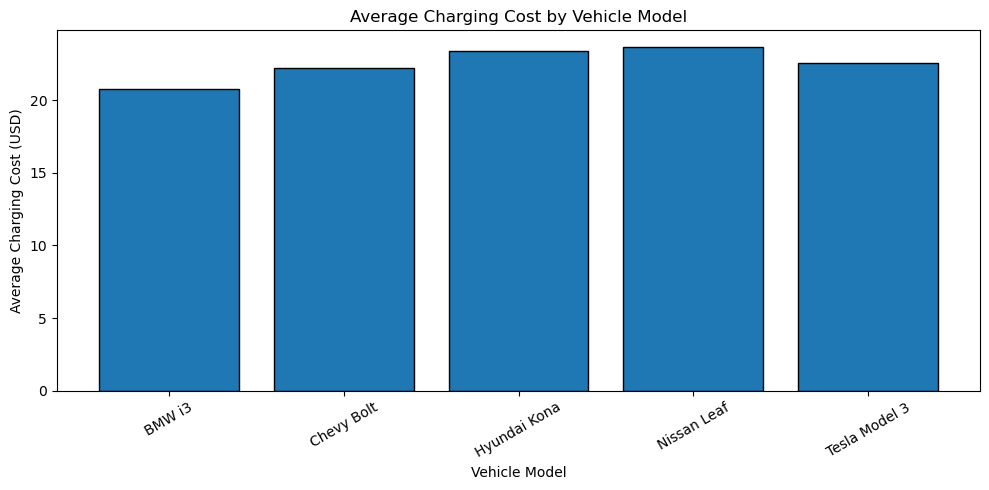

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    vehicle_performance.index,
    vehicle_performance["Average_Cost"],
    edgecolor="black"
)

plt.xlabel("Vehicle Model")
plt.ylabel("Average Charging Cost (USD)")
plt.title("Average Charging Cost by Vehicle Model")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 18: Vehicle-wise Average Charging Duration

In this step, we visualize the average calculated charging duration for each vehicle model.

This comparison helps us understand how charging duration varies across different vehicle models.

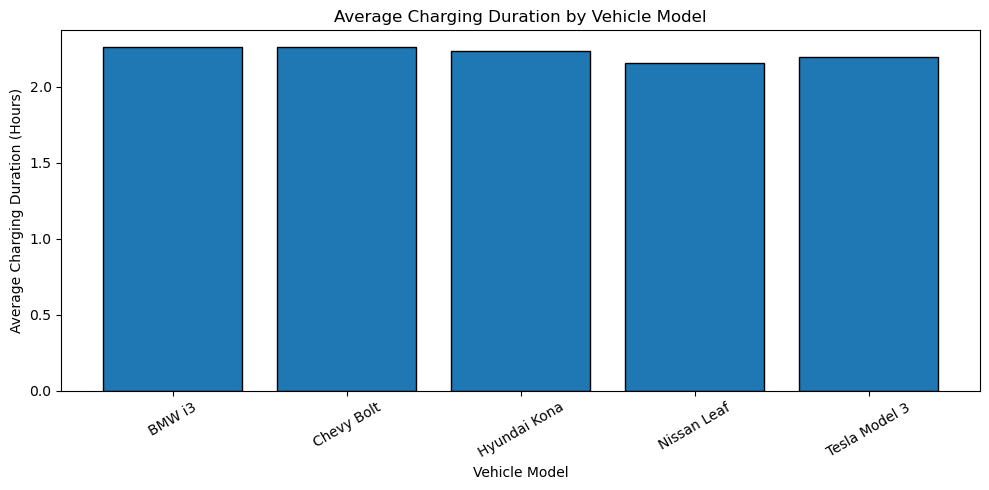

In [22]:
plt.figure(figsize=(10, 5))

plt.bar(
    vehicle_performance.index,
    vehicle_performance["Average_Duration"],
    edgecolor="black"
)

plt.xlabel("Vehicle Model")
plt.ylabel("Average Charging Duration (Hours)")
plt.title("Average Charging Duration by Vehicle Model")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 19: Location-wise Performance Analysis

In this step, we analyze EV charging activity across different locations.

We calculate:
- Total Charging Sessions
- Average Energy Consumed
- Average Charging Cost
- Average Charging Duration

This analysis helps compare charging patterns across different cities.

In [23]:
location_performance = df.groupby("Charging Station Location").agg(
    Total_Sessions=("User ID", "count"),
    Average_Energy=("Energy Consumed (kWh)", "mean"),
    Average_Cost=("Charging Cost (USD)", "mean"),
    Average_Duration=("Calculated Duration (hours)", "mean")
).round(2)

location_performance

,Total_Sessions,Average_Energy,Average_Cost,Average_Duration
Charging Station Location,,,,
Chicago,242,43.46,23.72,2.21
Houston,262,44.06,22.09,2.31
Los Angeles,297,41.48,22.54,2.23
New York,255,42.25,22.50,2.20
San Francisco,264,42.19,21.99,2.18


## Step 20: Location-wise Average Energy Consumption

In this step, we visualize the average energy consumed per charging session across different cities.

This comparison helps identify differences in average charging energy across locations.

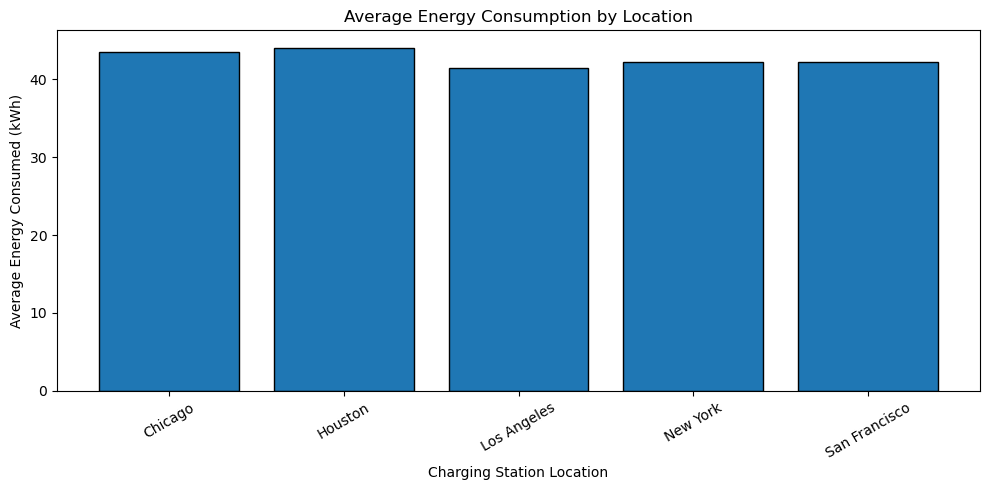

In [24]:
plt.figure(figsize=(10, 5))

plt.bar(
    location_performance.index,
    location_performance["Average_Energy"],
    edgecolor="black"
)

plt.xlabel("Charging Station Location")
plt.ylabel("Average Energy Consumed (kWh)")
plt.title("Average Energy Consumption by Location")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 21: Location-wise Average Charging Cost

In this step, we visualize the average recorded charging cost per session across different cities.

This comparison helps identify variations in average charging costs across locations.

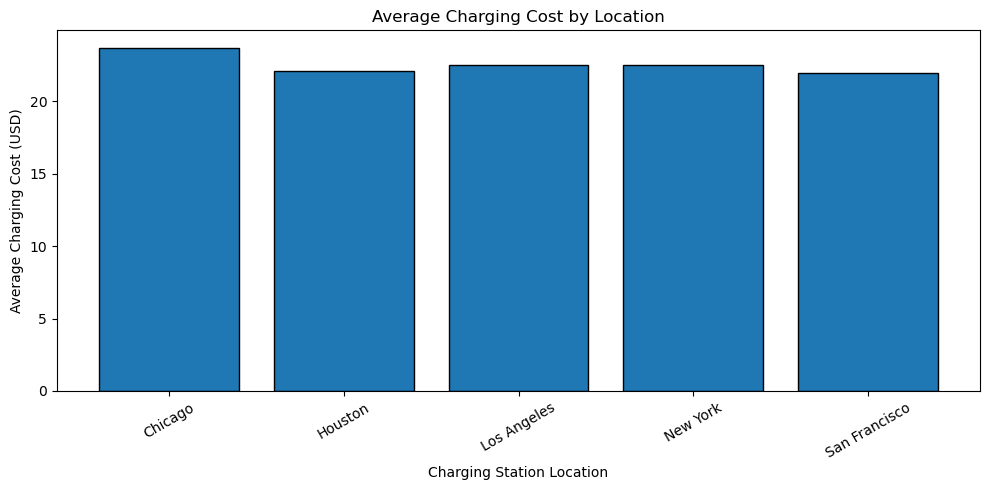

In [25]:
plt.figure(figsize=(10, 5))

plt.bar(
    location_performance.index,
    location_performance["Average_Cost"],
    edgecolor="black"
)

plt.xlabel("Charging Station Location")
plt.ylabel("Average Charging Cost (USD)")
plt.title("Average Charging Cost by Location")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 22: Location-wise Average Charging Duration

In this step, we visualize the average calculated charging duration across different cities.

This comparison helps us understand how charging duration varies by location in the dataset.

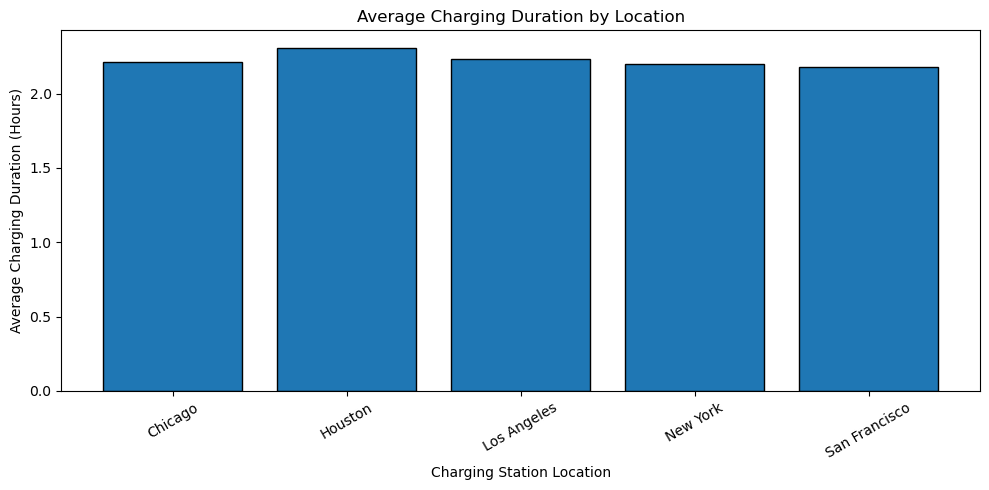

In [26]:
plt.figure(figsize=(10, 5))

plt.bar(
    location_performance.index,
    location_performance["Average_Duration"],
    edgecolor="black"
)

plt.xlabel("Charging Station Location")
plt.ylabel("Average Charging Duration (Hours)")
plt.title("Average Charging Duration by Location")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 23: Charger Type-wise Performance Analysis

In this step, we analyze charging performance across different charger types.

We calculate:
- Total Charging Sessions
- Average Energy Consumed
- Average Charging Cost
- Average Charging Duration

This analysis helps compare charging patterns across different charger types.

In [27]:
charger_performance = df.groupby("Charger Type").agg(
    Total_Sessions=("User ID", "count"),
    Average_Energy=("Energy Consumed (kWh)", "mean"),
    Average_Cost=("Charging Cost (USD)", "mean"),
    Average_Duration=("Calculated Duration (hours)", "mean")
).round(2)

charger_performance

,Total_Sessions,Average_Energy,Average_Cost,Average_Duration
Charger Type,,,,
DC Fast Charger,430,41.37,23.60,2.24
Level 1,459,41.66,21.66,2.23
Level 2,431,44.97,22.45,2.21


## Step 24: Charger Type-wise Average Energy Consumption

In this step, we visualize the average energy consumed per charging session for each charger type.

This comparison helps us understand differences in energy consumption across charger types.

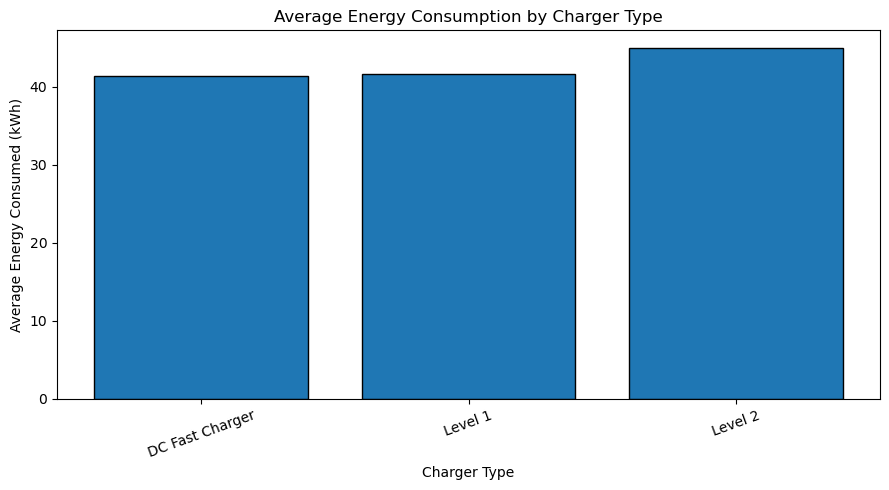

In [28]:
plt.figure(figsize=(9, 5))

plt.bar(
    charger_performance.index,
    charger_performance["Average_Energy"],
    edgecolor="black"
)

plt.xlabel("Charger Type")
plt.ylabel("Average Energy Consumed (kWh)")
plt.title("Average Energy Consumption by Charger Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Step 25: Charger Type-wise Average Charging Cost

In this step, we visualize the average recorded charging cost per session for each charger type.

This comparison helps us understand how average charging costs vary across different charger types.

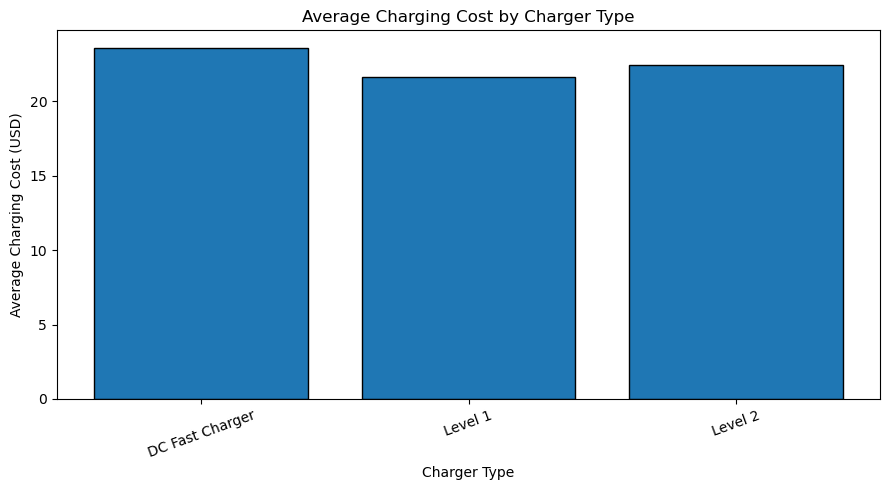

In [29]:
plt.figure(figsize=(9, 5))

plt.bar(
    charger_performance.index,
    charger_performance["Average_Cost"],
    edgecolor="black"
)

plt.xlabel("Charger Type")
plt.ylabel("Average Charging Cost (USD)")
plt.title("Average Charging Cost by Charger Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Step 26: Charger Type-wise Average Charging Duration

In this step, we visualize the average calculated charging duration for each charger type.

This comparison helps us understand how charging duration varies across different charger types.

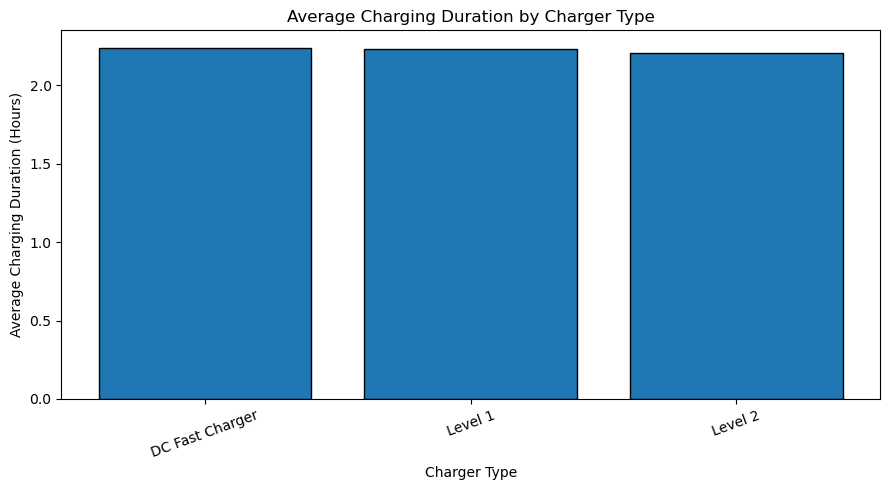

In [30]:
plt.figure(figsize=(9, 5))

plt.bar(
    charger_performance.index,
    charger_performance["Average_Duration"],
    edgecolor="black"
)

plt.xlabel("Charger Type")
plt.ylabel("Average Charging Duration (Hours)")
plt.title("Average Charging Duration by Charger Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Step 27: User Type-wise Performance Analysis

In this step, we analyze EV charging activity across different user types.

We calculate:
- Total Charging Sessions
- Average Energy Consumed
- Average Charging Cost
- Average Charging Duration

This analysis helps us understand differences in charging patterns across user categories.

In [31]:
user_performance = df.groupby("User Type").agg(
    Total_Sessions=("User ID", "count"),
    Average_Energy=("Energy Consumed (kWh)", "mean"),
    Average_Cost=("Charging Cost (USD)", "mean"),
    Average_Duration=("Calculated Duration (hours)", "mean")
).round(2)

user_performance

,Total_Sessions,Average_Energy,Average_Cost,Average_Duration
User Type,,,,
Casual Driver,407,44.41,22.68,2.28
Commuter,476,41.42,22.75,2.18
Long-Distance Traveler,437,42.34,22.21,2.23


## Step 28: User Type-wise Average Energy Consumption

In this step, we visualize the average energy consumed per charging session across different user types.

This comparison helps us understand differences in charging energy consumption among user categories.


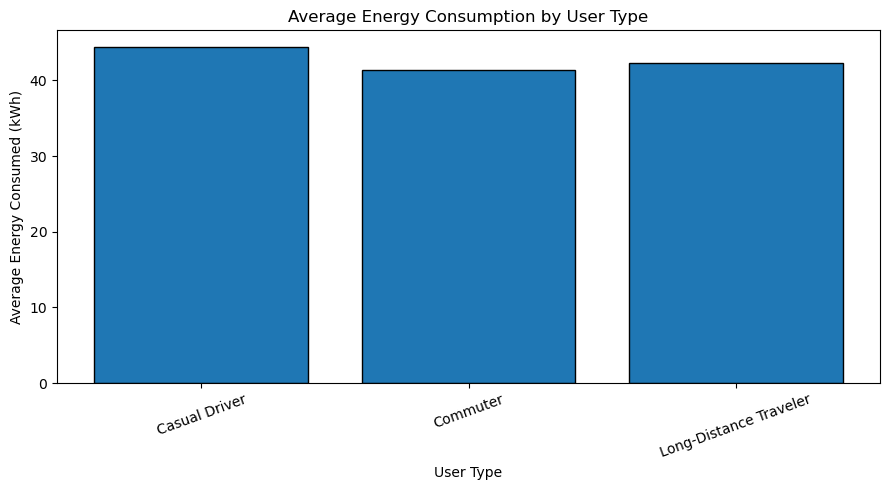

In [32]:
plt.figure(figsize=(9, 5))

plt.bar(
    user_performance.index,
    user_performance["Average_Energy"],
    edgecolor="black"
)

plt.xlabel("User Type")
plt.ylabel("Average Energy Consumed (kWh)")
plt.title("Average Energy Consumption by User Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Step 29: User Type-wise Average Charging Cost

In this step, we visualize the average recorded charging cost per session across different user types.

This comparison helps us understand how average charging costs vary among user categories.

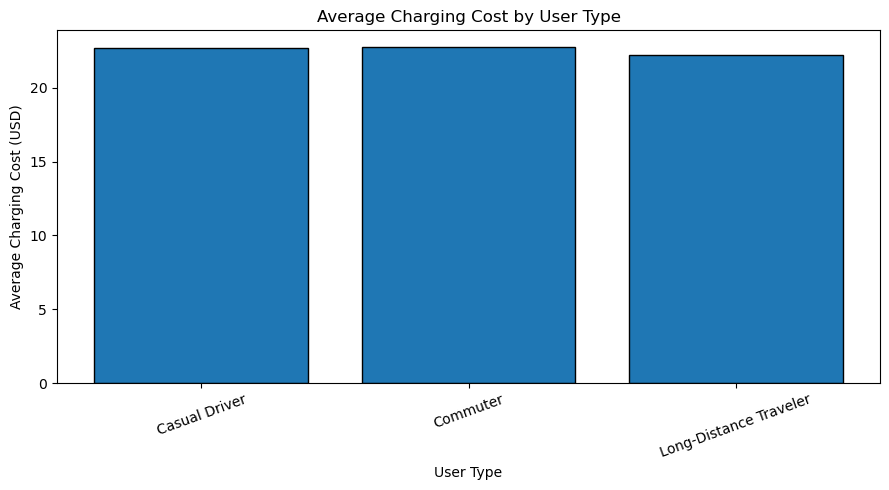

In [33]:
plt.figure(figsize=(9, 5))

plt.bar(
    user_performance.index,
    user_performance["Average_Cost"],
    edgecolor="black"
)

plt.xlabel("User Type")
plt.ylabel("Average Charging Cost (USD)")
plt.title("Average Charging Cost by User Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Step 30: User Type-wise Average Charging Duration

In this step, we visualize the average calculated charging duration for each user type.

This comparison helps us understand how charging duration varies across different user categories.

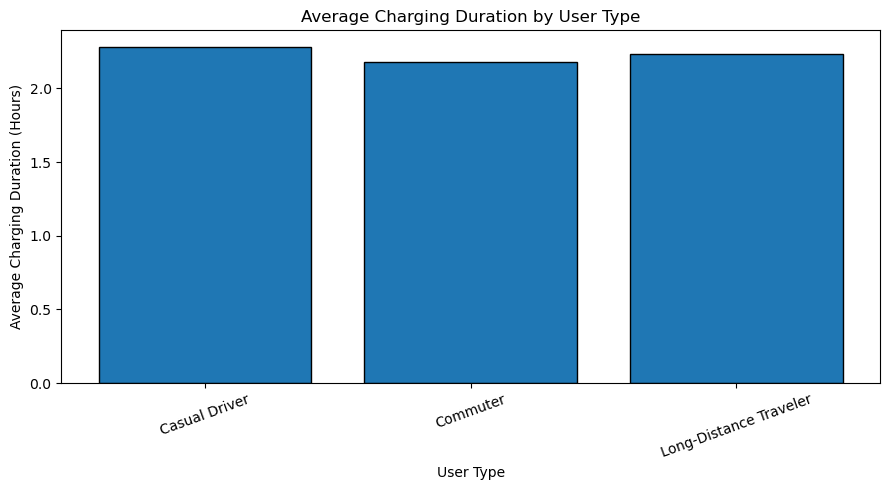

In [34]:
plt.figure(figsize=(9, 5))

plt.bar(
    user_performance.index,
    user_performance["Average_Duration"],
    edgecolor="black"
)

plt.xlabel("User Type")
plt.ylabel("Average Charging Duration (Hours)")
plt.title("Average Charging Duration by User Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Step 31: Time of Day-wise Performance Analysis

In this step, we analyze EV charging activity across different times of the day.

We calculate:
- Total Charging Sessions
- Average Energy Consumed
- Average Charging Cost
- Average Charging Duration

This analysis helps us compare charging patterns during Night, Morning, Afternoon, and Evening.

In [35]:
time_performance = df.groupby("Time of Day").agg(
    Total_Sessions=("User ID", "count"),
    Average_Energy=("Energy Consumed (kWh)", "mean"),
    Average_Cost=("Charging Cost (USD)", "mean"),
    Average_Duration=("Calculated Duration (hours)", "mean")
).reindex(["Night", "Morning", "Afternoon", "Evening"]).round(2)

time_performance

,Total_Sessions,Average_Energy,Average_Cost,Average_Duration
Time of Day,,,,
Night,330,42.43,22.14,2.21
Morning,330,42.17,22.35,2.27
Afternoon,330,42.83,23.15,2.13
Evening,330,43.15,22.57,2.29


## Step 32: Time of Day-wise Charging Sessions

In this step, we visualize the total number of charging sessions during Night, Morning, Afternoon, and Evening.

This analysis helps compare charging activity across different time periods.

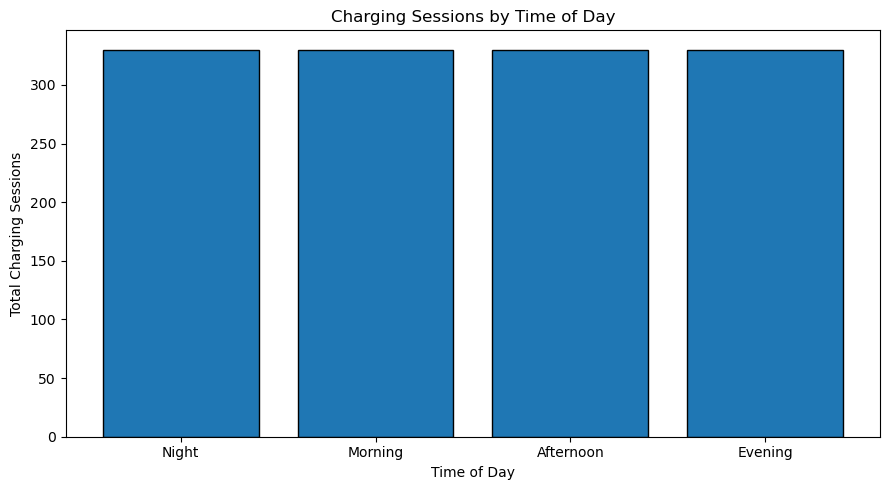

In [36]:
plt.figure(figsize=(9, 5))

plt.bar(
    time_performance.index,
    time_performance["Total_Sessions"],
    edgecolor="black"
)

plt.xlabel("Time of Day")
plt.ylabel("Total Charging Sessions")
plt.title("Charging Sessions by Time of Day")
plt.tight_layout()
plt.show()

## Step 33: Time of Day-wise Average Energy Consumption

In this step, we visualize the average energy consumed per charging session during different times of the day.

This comparison helps us understand how average energy consumption varies across time periods.

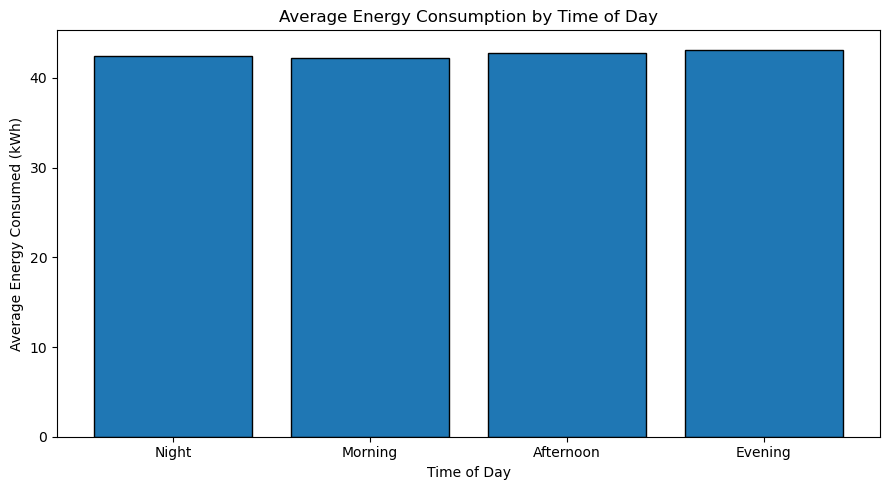

In [37]:
plt.figure(figsize=(9, 5))

plt.bar(
    time_performance.index,
    time_performance["Average_Energy"],
    edgecolor="black"
)

plt.xlabel("Time of Day")
plt.ylabel("Average Energy Consumed (kWh)")
plt.title("Average Energy Consumption by Time of Day")
plt.tight_layout()
plt.show()

## Step 34: Time of Day-wise Average Charging Cost

In this step, we visualize the average recorded charging cost per session during different times of the day.

This comparison helps us understand how average charging costs vary across different time periods.

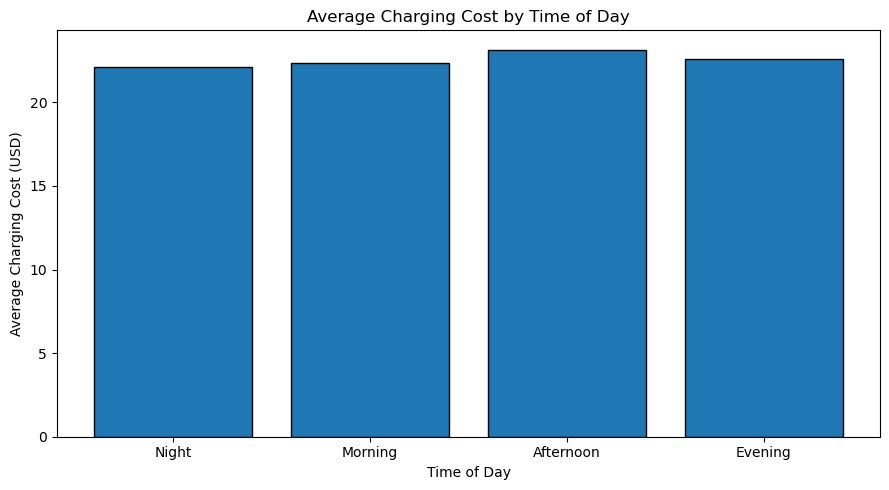

In [38]:
plt.figure(figsize=(9, 5))

plt.bar(
    time_performance.index,
    time_performance["Average_Cost"],
    edgecolor="black"
)

plt.xlabel("Time of Day")
plt.ylabel("Average Charging Cost (USD)")
plt.title("Average Charging Cost by Time of Day")
plt.tight_layout()
plt.show()

## Step 35: Time of Day-wise Average Charging Duration

In this step, we visualize the average calculated charging duration during different times of the day.

This comparison helps us understand how charging duration varies across different time periods.

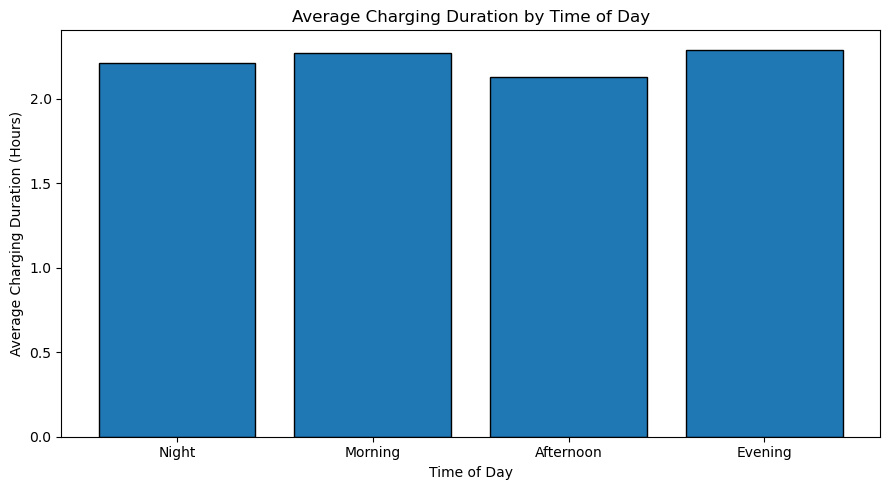

In [39]:
plt.figure(figsize=(9, 5))

plt.bar(
    time_performance.index,
    time_performance["Average_Duration"],
    edgecolor="black"
)

plt.xlabel("Time of Day")
plt.ylabel("Average Charging Duration (Hours)")
plt.title("Average Charging Duration by Time of Day")
plt.tight_layout()
plt.show()

## Step 36: Day-wise Performance Analysis

In this step, we analyze EV charging activity across different days of the week.

We calculate:
- Total Charging Sessions
- Average Energy Consumed
- Average Charging Cost
- Average Charging Duration

This analysis helps compare charging patterns across weekdays and weekends.

In [40]:
day_performance = df.groupby("Day of Week").agg(
    Total_Sessions=("User ID", "count"),
    Average_Energy=("Energy Consumed (kWh)", "mean"),
    Average_Cost=("Charging Cost (USD)", "mean"),
    Average_Duration=("Calculated Duration (hours)", "mean")
).reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]).round(2)

day_performance

,Total_Sessions,Average_Energy,Average_Cost,Average_Duration
Day of Week,,,,
Monday,192,42.68,23.13,2.25
Tuesday,192,41.43,24.30,2.22
Wednesday,192,44.02,22.56,2.25
Thursday,192,42.53,22.18,2.26
Friday,192,39.84,22.38,2.22
Saturday,192,43.02,22.70,2.18
Sunday,168,45.34,20.32,2.20


## Step 37: Day-wise Charging Sessions

In this step, we visualize the total number of charging sessions recorded on each day of the week.

This comparison helps us understand how charging activity is distributed across different days.

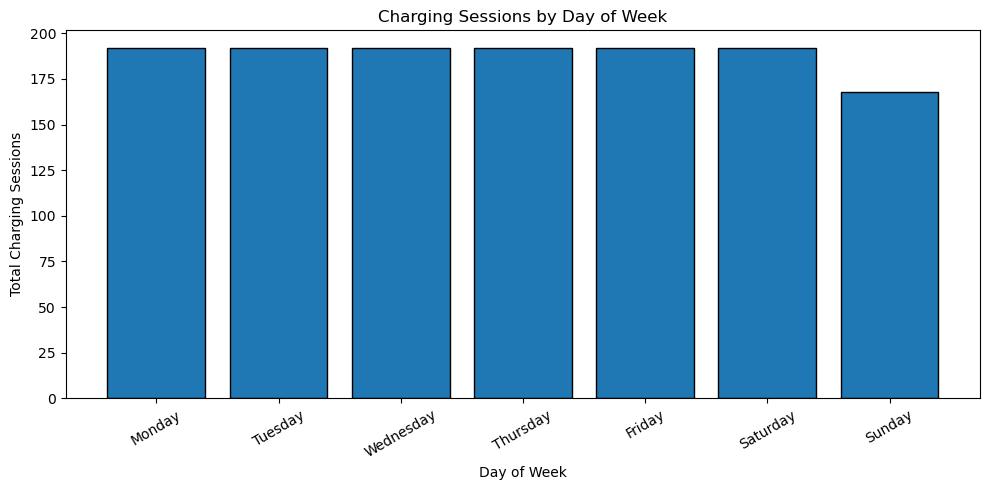

In [41]:
plt.figure(figsize=(10, 5))

plt.bar(
    day_performance.index,
    day_performance["Total_Sessions"],
    edgecolor="black"
)

plt.xlabel("Day of Week")
plt.ylabel("Total Charging Sessions")
plt.title("Charging Sessions by Day of Week")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 38: Day-wise Average Energy Consumption

In this step, we visualize the average energy consumed per charging session on each day of the week.

This comparison helps us understand how average charging energy varies across different days.

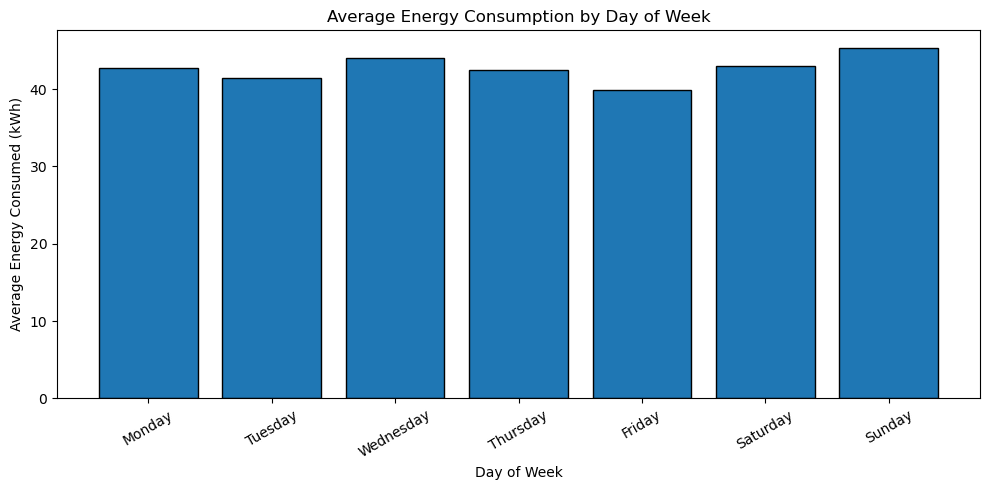

In [42]:
plt.figure(figsize=(10, 5))

plt.bar(
    day_performance.index,
    day_performance["Average_Energy"],
    edgecolor="black"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Energy Consumed (kWh)")
plt.title("Average Energy Consumption by Day of Week")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 39: Day-wise Average Charging Cost

In this step, we visualize the average recorded charging cost per session on each day of the week.

This comparison helps us understand how average charging costs vary across different days.

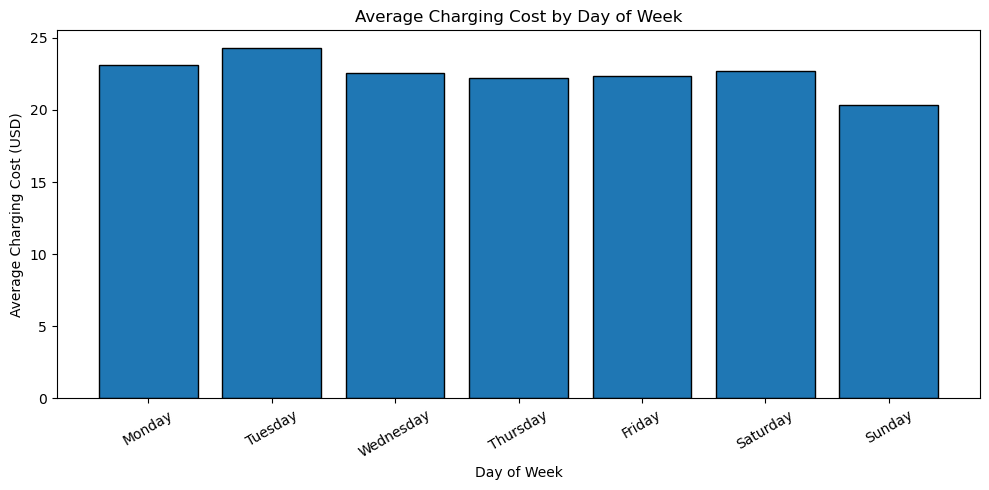

In [43]:
plt.figure(figsize=(10, 5))

plt.bar(
    day_performance.index,
    day_performance["Average_Cost"],
    edgecolor="black"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Charging Cost (USD)")
plt.title("Average Charging Cost by Day of Week")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 40: Day-wise Average Charging Duration

In this step, we visualize the average calculated charging duration for each day of the week.

This comparison helps us understand how charging duration varies across different days.

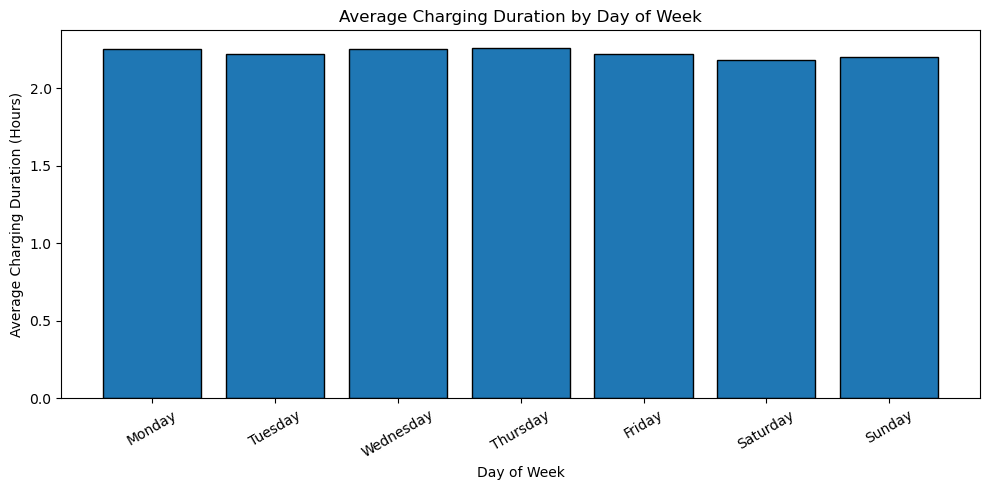

In [44]:
plt.figure(figsize=(10, 5))

plt.bar(
    day_performance.index,
    day_performance["Average_Duration"],
    edgecolor="black"
)

plt.xlabel("Day of Week")
plt.ylabel("Average Charging Duration (Hours)")
plt.title("Average Charging Duration by Day of Week")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Step 41: Weekday vs Weekend Analysis

In this step, we divide charging sessions into two groups: Weekdays and Weekends.

We calculate:
- Total Charging Sessions
- Average Energy Consumed
- Average Charging Cost
- Average Charging Duration

This analysis helps compare charging patterns between weekdays and weekends.

In [45]:
df["Day Category"] = np.where(
    df["Day of Week"].isin(["Saturday", "Sunday"]),
    "Weekend",
    "Weekday"
)

weekday_weekend_analysis = df.groupby("Day Category").agg(
    Total_Sessions=("User ID", "count"),
    Average_Energy=("Energy Consumed (kWh)", "mean"),
    Average_Cost=("Charging Cost (USD)", "mean"),
    Average_Duration=("Calculated Duration (hours)", "mean")
).reindex(["Weekday", "Weekend"]).round(2)

weekday_weekend_analysis

,Total_Sessions,Average_Energy,Average_Cost,Average_Duration
Day Category,,,,
Weekday,960,42.1,22.91,2.24
Weekend,360,44.1,21.59,2.19


## Step 42: Weekday vs Weekend Charging Sessions

In this step, we visualize the total charging sessions recorded on weekdays and weekends.

This comparison helps us understand how charging activity is distributed between weekdays and weekends.


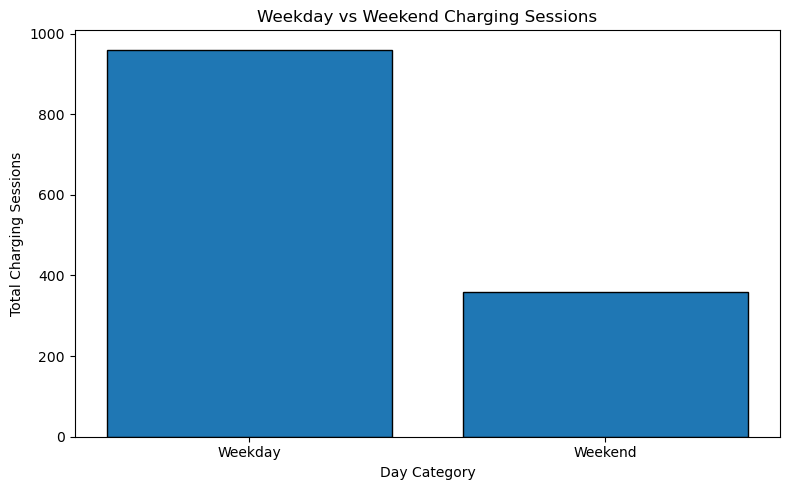

In [46]:
plt.figure(figsize=(8, 5))

plt.bar(
    weekday_weekend_analysis.index,
    weekday_weekend_analysis["Total_Sessions"],
    edgecolor="black"
)

plt.xlabel("Day Category")
plt.ylabel("Total Charging Sessions")
plt.title("Weekday vs Weekend Charging Sessions")
plt.tight_layout()
plt.show()

## Step 43: Weekday vs Weekend Average Energy Consumption

In this step, we visualize the average energy consumed per charging session on weekdays and weekends.

This comparison helps us understand whether average charging energy differs between weekdays and weekends.

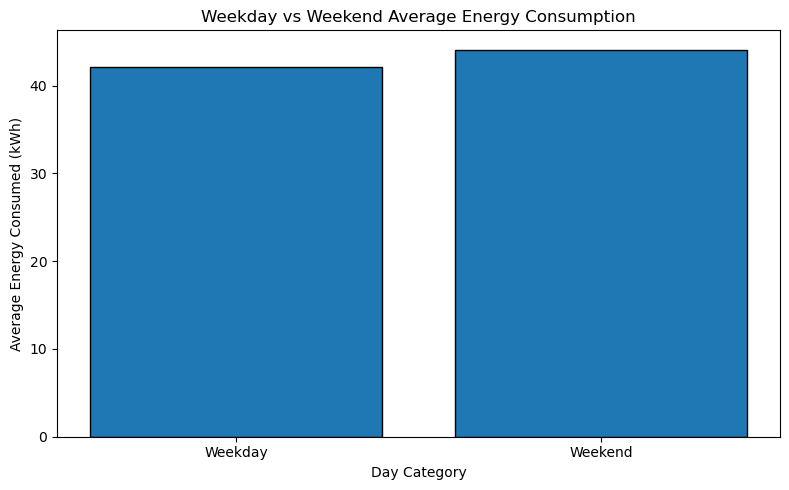

In [47]:
plt.figure(figsize=(8, 5))

plt.bar(
    weekday_weekend_analysis.index,
    weekday_weekend_analysis["Average_Energy"],
    edgecolor="black"
)

plt.xlabel("Day Category")
plt.ylabel("Average Energy Consumed (kWh)")
plt.title("Weekday vs Weekend Average Energy Consumption")
plt.tight_layout()
plt.show()

## Step 44: Weekday vs Weekend Average Charging Cost

In this step, we visualize the average recorded charging cost per session on weekdays and weekends.

This comparison helps us understand whether average charging costs differ between weekdays and weekends.

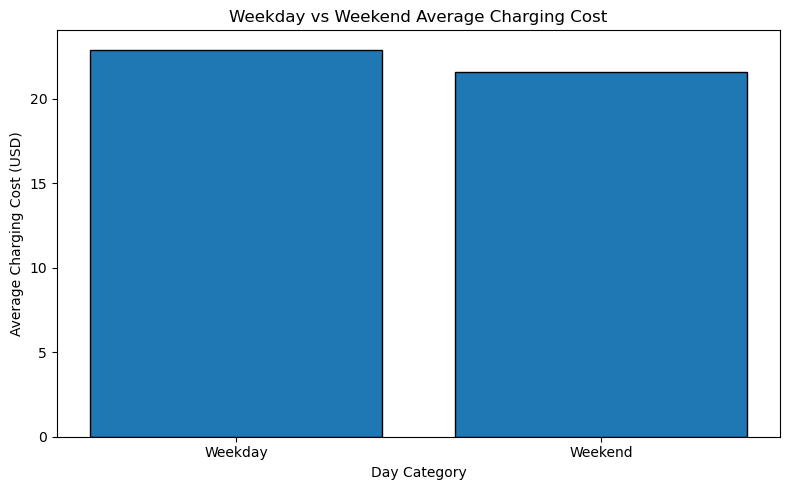

In [48]:
plt.figure(figsize=(8, 5))

plt.bar(
    weekday_weekend_analysis.index,
    weekday_weekend_analysis["Average_Cost"],
    edgecolor="black"
)

plt.xlabel("Day Category")
plt.ylabel("Average Charging Cost (USD)")
plt.title("Weekday vs Weekend Average Charging Cost")
plt.tight_layout()
plt.show()

## Step 45: Weekday vs Weekend Average Charging Duration

In this step, we visualize the average calculated charging duration on weekdays and weekends.

This comparison helps us understand whether charging duration differs between weekdays and weekends.

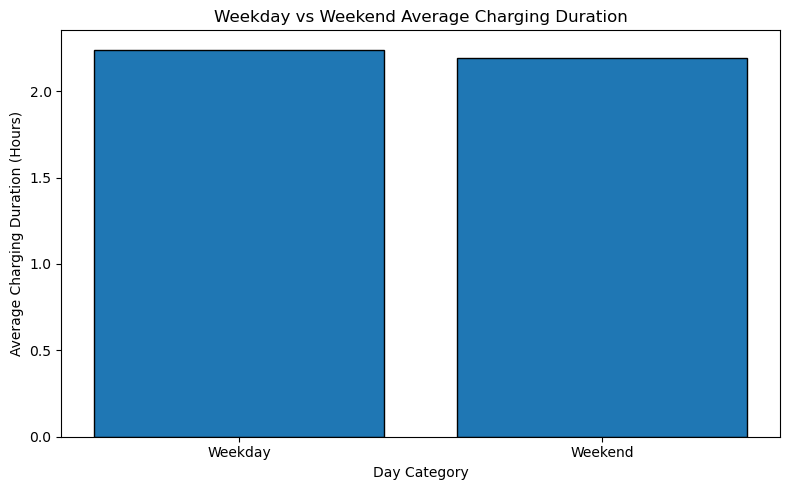

In [49]:
plt.figure(figsize=(8, 5))

plt.bar(
    weekday_weekend_analysis.index,
    weekday_weekend_analysis["Average_Duration"],
    edgecolor="black"
)

plt.xlabel("Day Category")
plt.ylabel("Average Charging Duration (Hours)")
plt.title("Weekday vs Weekend Average Charging Duration")
plt.tight_layout()
plt.show()

## Step 46: Final KPI Summary

In this step, we calculate and display key performance indicators (KPIs) from the EV charging dataset.

These metrics provide an overall summary of charging sessions, energy consumption, charging costs, duration, vehicles, and locations.

In [50]:
final_kpis = {
    "Total Charging Sessions": len(df),
    "Unique Users": df["User ID"].nunique(),
    "Vehicle Models": df["Vehicle Model"].nunique(),
    "Charging Stations": df["Charging Station ID"].nunique(),
    "Charging Locations": df["Charging Station Location"].nunique(),
    "Total Energy Consumed (kWh)": round(
        df["Energy Consumed (kWh)"].sum(), 2
    ),
    "Average Energy per Session (kWh)": round(
        df["Energy Consumed (kWh)"].mean(), 2
    ),
    "Average Charging Cost (USD)": round(
        df["Charging Cost (USD)"].mean(), 2
    ),
    "Total Recorded Charging Cost (USD)": round(
        df["Charging Cost (USD)"].sum(), 2
    ),
    "Average Calculated Duration (Hours)": round(
        df["Calculated Duration (hours)"].mean(), 2
    )
}

kpi_summary = pd.DataFrame(
    final_kpis.items(),
    columns=["KPI", "Value"]
)

kpi_summary

,KPI,Value
0,Total Charging Sessions,1320.00
1,Unique Users,1320.00
2,Vehicle Models,5.00
3,Charging Stations,462.00
4,Charging Locations,5.00
5,Total Energy Consumed (kWh),56291.82
6,Average Energy per Session (kWh),42.65
7,Average Charging Cost (USD),22.55
8,Total Recorded Charging Cost (USD),29767.78
9,Average Calculated Duration (Hours),2.23


## Step 47: Final Findings & Key Observations

### 1. Dataset Overview
- Total charging sessions: 1,320
- Unique users: 1,320
- Vehicle models: 5
- Charging stations: 462
- Charging locations: 5

### 2. Energy Consumption
- Total recorded energy consumption: 56,291.82 kWh
- Average energy consumption per session: 42.65 kWh
- Tesla Model 3 has the highest average energy consumption among vehicle models.

### 3. Charging Cost
- Average recorded charging cost: $22.55
- Total recorded charging cost: $29,767.78
- Nissan Leaf has the highest average charging cost among vehicle models.

### 4. Charging Duration
- Average calculated charging duration: 2.23 hours.
- BMW i3 has the highest average calculated duration among vehicle models.

### 5. Location Analysis
- Los Angeles has the highest number of charging sessions.
- Chicago has the lowest number of charging sessions.

### 6. Data Quality Observations
- Several numerical features contain potential outliers.
- Charging duration and energy consumption show inconsistencies.
- Time-of-day categories have an exactly equal distribution.
- Charging station records are spread across many stations, with relatively few repeated observations per station.

### 7. Important Limitations
- The dataset contains only 1,320 records.
- The dataset has substantial inconsistencies and appears artificially structured.
- Results should be treated as exploratory findings, not verified real-world EV network performance.
- Correlation does not establish causation.
- Potential outliers have not been automatically removed.

## Step 48: Advanced Data Analysis Conclusion

Advanced Data Analysis was performed to explore numerical relationships, identify potential outliers, and compare charging performance across vehicle models, locations, charger types, user categories, and time periods.

The analysis provided an overview of energy consumption, charging costs, charging duration, and charging activity patterns.

Several data quality limitations were identified, including unusual distributions and inconsistencies between recorded and calculated values.

The findings will be used as a foundation for developing an interactive Power BI dashboard.

All conclusions should be interpreted within the limitations of the available dataset.